# Getting Financial Data - Pandas Datareader

### Introduction:

This time you will get data from a website.


### Step 1. Import the necessary libraries

In [92]:
# ! pip install yfinance

In [141]:
import requests
from datetime import datetime
import yfinance as yf
import pandas as pd

### Step 2. Create your time range (start and end variables). The start date should be 01/01/2015 and the end should today (whatever your today is).

In [142]:
start = datetime(2015,1,1)
end = datetime.today()

### Step 3. Get an API key for one of the APIs that are supported by Pandas Datareader, preferably for AlphaVantage.

If you do not have an API key for any of the supported APIs, it is easiest to get one for [AlphaVantage](https://www.alphavantage.co/support/#api-key). (Note that the API key is shown directly after the signup. You do *not* receive it via e-mail.)

(For a full list of the APIs that are supported by Pandas Datareader, [see here](https://pydata.github.io/pandas-datareader/readers/index.html). As the APIs are provided by third parties, this list may change.)

### Step 4. Use Pandas Datarader to read the daily time series for the Apple stock (ticker symbol AAPL) between 01/01/2015 and today, assign it to df_apple and print it.

In [143]:
df_apple = yf.download('AAPL',start=start,end=end)
df_apple # this is multiindex and i want to convert flatten it
if isinstance(df_apple.columns,pd.MultiIndex):
    df_apple.columns = df_apple.columns.get_level_values(0)
df_apple.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,24.214888,24.682220,23.776348,24.671145,212818400
2015-01-05,23.532721,24.064284,23.346674,23.984549,257142000
2015-01-06,23.534941,23.794077,23.173920,23.596956,263188400
2015-01-07,23.864952,23.964619,23.632393,23.743135,160423600
2015-01-08,24.781895,24.839481,24.075359,24.192747,237458000


### Step 5. Add a new column "stock" to the dataframe and add the ticker symbol

In [144]:
df_apple['stock'] = 'AAPL'

In [145]:
df_apple

Price,Close,High,Low,Open,Volume,stock
Date,,,,,,
2015-01-02,24.214888,24.682220,23.776348,24.671145,212818400,AAPL
2015-01-05,23.532721,24.064284,23.346674,23.984549,257142000,AAPL
2015-01-06,23.534941,23.794077,23.173920,23.596956,263188400,AAPL
2015-01-07,23.864952,23.964619,23.632393,23.743135,160423600,AAPL
2015-01-08,24.781895,24.839481,24.075359,24.192747,237458000,AAPL
...,...,...,...,...,...,...
2026-03-18,249.940002,254.940002,249.000000,252.630005,35757900,AAPL
2026-03-19,248.960007,251.830002,247.300003,249.399994,34864100,AAPL
2026-03-20,247.990005,249.199997,246.000000,247.979996,88331100,AAPL


### Step 6. Repeat the two previous steps for a few other stocks, always creating a new dataframe: Tesla, IBM and Microsoft. (Ticker symbols TSLA, IBM and MSFT.)

In [146]:
df_micro = yf.download('MSFT',start=start,end=end)
df_micro # this is multiindex and i want to convert flatten it
if isinstance(df_micro.columns,pd.MultiIndex):
    df_micro.columns = df_micro.columns.get_level_values(0)
df_micro.head()
df_micro['stock'] = 'MSFT'

[*********************100%***********************]  1 of 1 completed


In [147]:
df_tesla = yf.download('TSLA',start=start,end=end)
df_tesla # this is multiindex and i want to convert flatten it
if isinstance(df_tesla.columns,pd.MultiIndex):
    df_tesla.columns = df_tesla.columns.get_level_values(0)
df_tesla.head()
df_tesla['stock'] = 'TSLA'

[*********************100%***********************]  1 of 1 completed


In [148]:
df_ibm = yf.download('IBM',start=start,end=end)
df_ibm # this is multiindex and i want to convert flatten it
if isinstance(df_ibm.columns,pd.MultiIndex):
    df_ibm.columns = df_ibm.columns.get_level_values(0)
df_ibm.head()
df_ibm['stock'] = 'IBM'

[*********************100%***********************]  1 of 1 completed


### Step 7. Combine the four separate dataFrames into one combined dataFrame df that holds the information for all four stocks

In [149]:
df = pd.concat([df_apple, df_tesla, df_ibm, df_micro], axis=0)
df.head()

Price,Close,High,Low,Open,Volume,stock
Date,,,,,,
2015-01-02,24.214888,24.682220,23.776348,24.671145,212818400,AAPL
2015-01-05,23.532721,24.064284,23.346674,23.984549,257142000,AAPL
2015-01-06,23.534941,23.794077,23.173920,23.596956,263188400,AAPL
2015-01-07,23.864952,23.964619,23.632393,23.743135,160423600,AAPL
2015-01-08,24.781895,24.839481,24.075359,24.192747,237458000,AAPL


In [150]:
df.tail()

Price,Close,High,Low,Open,Volume,stock
Date,,,,,,
2026-03-18,391.790009,398.000000,391.000000,397.130005,25908500,MSFT
2026-03-19,389.019989,392.489990,387.059998,390.100006,25138800,MSFT
2026-03-20,381.869995,387.000000,380.119995,386.790009,50853200,MSFT
2026-03-23,383.000000,387.209991,381.679993,383.899994,29680100,MSFT
2026-03-24,372.739990,382.470001,371.850006,382.410004,40186581,MSFT


In [151]:
df.stock.unique()

array(['AAPL', 'TSLA', 'IBM', 'MSFT'], dtype=object)

### Step 8. Shift the stock column into the index (making it a multi-level index consisting of the ticker symbol and the date).

In [157]:
# df = df.set_index('stock',append=True)

# Swap levels so stock comes first, then date
# df = df.swaplevel()
df = df.sort_index()

In [160]:
df.head()

Price                 Close       High        Low       Open     Volume
stock Date                                                             
AAPL  2015-01-02  24.214888  24.682220  23.776348  24.671145  212818400
      2015-01-05  23.532721  24.064284  23.346674  23.984549  257142000
      2015-01-06  23.534941  23.794077  23.173920  23.596956  263188400
      2015-01-07  23.864952  23.964619  23.632393  23.743135  160423600
      2015-01-08  24.781895  24.839481  24.075359  24.192747  237458000

### Step 7. Create a dataFrame called vol, with the volume values.

In [111]:
df.tail()

Price                  Close        High         Low        Open    Volume
stock Date                                                                
TSLA  2026-03-18  392.779999  403.070007  392.309998  399.000000  50853100
      2026-03-19  380.299988  387.269989  378.730011  387.269989  67078300
      2026-03-20  367.959991  379.890015  364.459991  379.850006  78628600
      2026-03-23  380.850006  385.329987  372.730011  373.089996  74606000
      2026-03-24  383.029999  387.470001  376.309998  376.695007  59674483

In [161]:
vol = df[['Volume']]
vol.head(10)

Price                Volume
stock Date                 
AAPL  2015-01-02  212818400
      2015-01-05  257142000
      2015-01-06  263188400
      2015-01-07  160423600
      2015-01-08  237458000
      2015-01-09  214798000
      2015-01-12  198603200
      2015-01-13  268367600
      2015-01-14  195826400
      2015-01-15  240056000

### Step 8. Aggregate the data of volume to weekly.
Hint: Be careful to not sum data from the same week of 2015 and other years.

In [162]:
weekly_vol = vol.groupby(level='stock').resample('W',level='Date').sum()
weekly_vol

Price                 Volume
stock Date                  
AAPL  2015-01-04   212818400
      2015-01-11  1133010000
      2015-01-18  1216906400
      2015-01-25   794948000
      2015-02-01  1863370800
...                      ...
TSLA  2026-03-01   293561800
      2026-03-08   301991600
      2026-03-15   308315400
      2026-03-22   301518800
      2026-03-29   134280483

[2348 rows x 1 columns]

### Step 9. Find all the volume traded in the year of 2015

In [172]:
import matplotlib.pyplot as plt

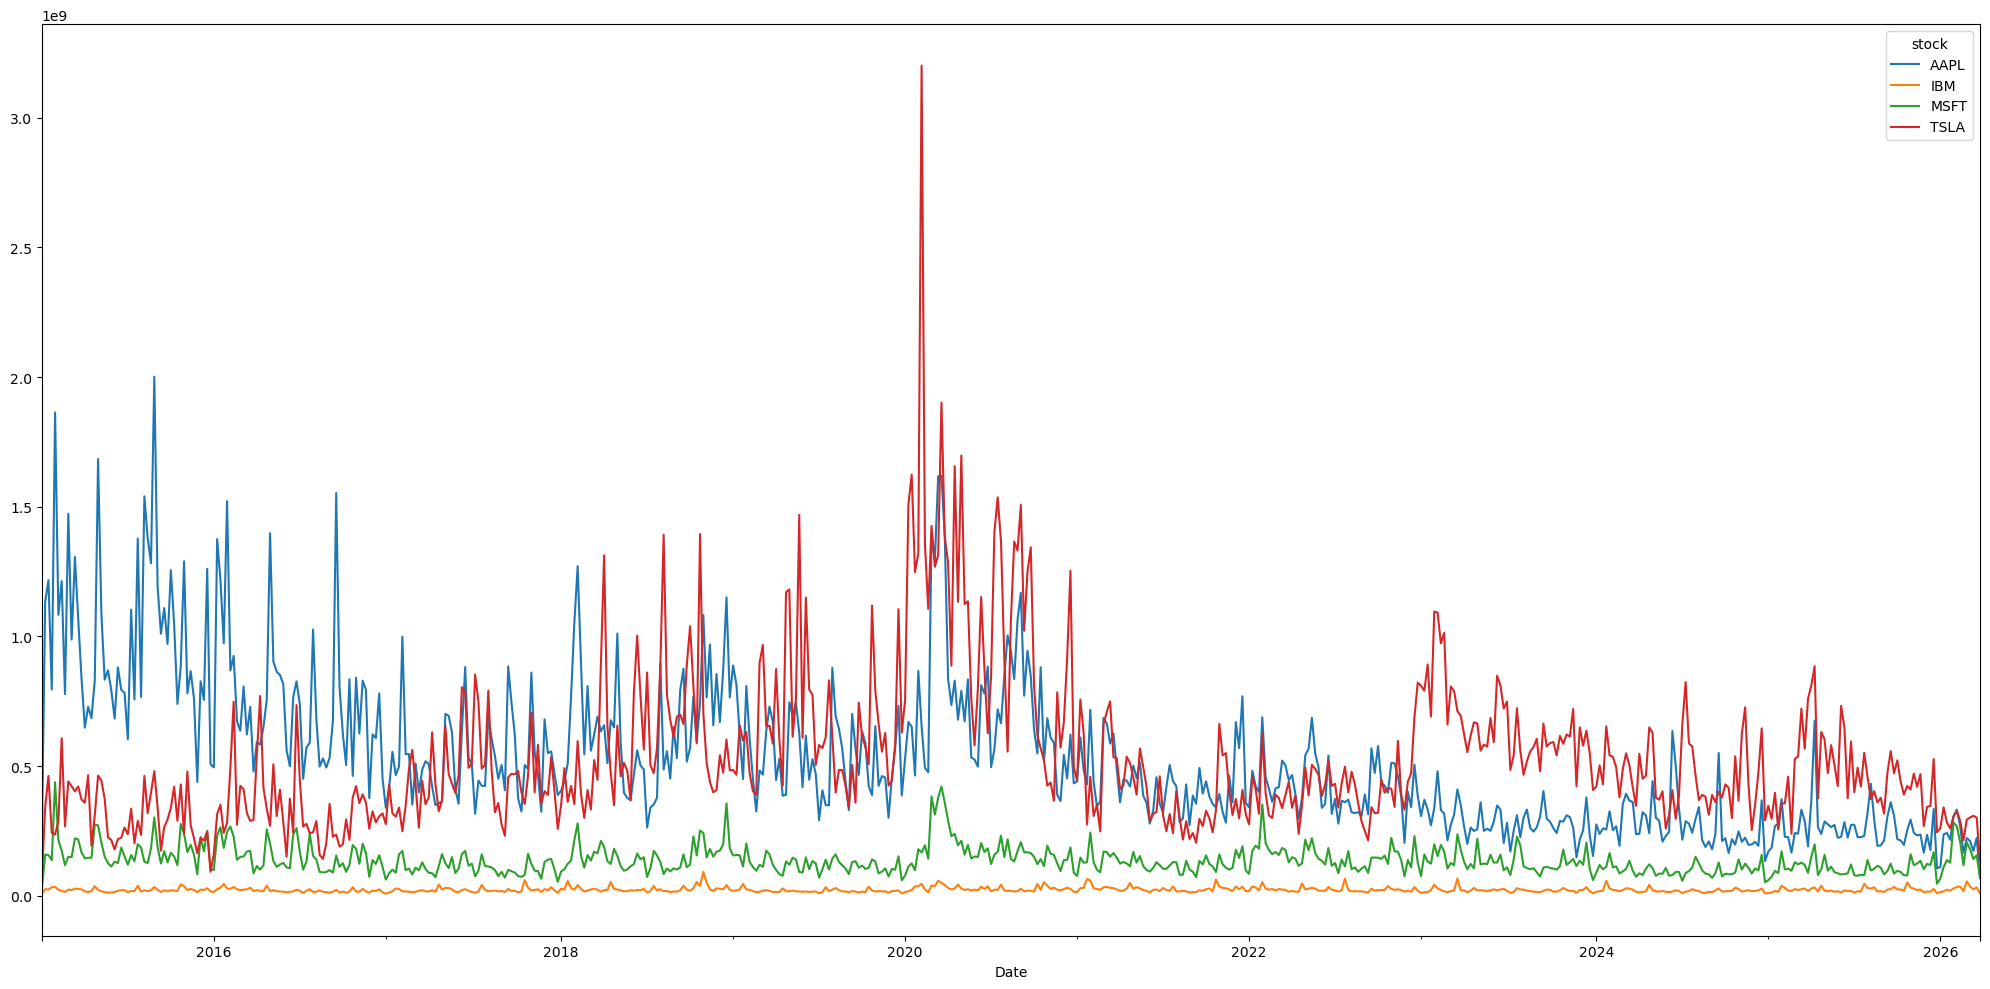

In [182]:
wv = weekly_vol['Volume'].unstack(level='stock')
# plt.figure(figsize=(20,10))
wv.plot(figsize=(20,10))
plt.tight_layout()
plt.show()

In [183]:
mask = vol.index.get_level_values('Date').year==2015
# mask
vol_2015 = vol[mask]
vol_2015
vol_2015_total = vol_2015.groupby(level='stock').sum()
vol_2015_total['Volume']

stock
AAPL    52264199600
IBM      1156439400
MSFT     9059455900
TSLA    16323267000
Name: Volume, dtype: int64